In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

df = pd.read_csv("../data/clean/clean_data.csv")

df.columns

Index(['marital_status', 'application_mode', 'application_order', 'course',
       'daytime_evening_attendance', 'previous_qualification',
       'previous_qualification_grade', 'nationality', 'mothers_qualification',
       'fathers_qualification', 'mothers_occupation', 'fathers_occupation',
       'admission_grade', 'displaced', 'educational_special_needs', 'debtor',
       'tuition_fees_up_to_date', 'gender', 'scholarship_holder',
       'age_at_enrollment', 'international',
       'curricular_units_1st_sem_credited',
       'curricular_units_1st_sem_enrolled',
       'curricular_units_1st_sem_evaluations',
       'curricular_units_1st_sem_approved', 'curricular_units_1st_sem_grade',
       'curricular_units_1st_sem_without_evaluations',
       'curricular_units_2nd_sem_credited',
       'curricular_units_2nd_sem_enrolled',
       'curricular_units_2nd_sem_evaluations',
       'curricular_units_2nd_sem_approved', 'curricular_units_2nd_sem_grade',
       'curricular_units_2nd_sem_wit

## Feature Selection and Exploratory Data Analysis

In [2]:
my_columns = [
    "scholarship_holder",
    "age_at_enrollment",
    "international",
    "curricular_units_1st_sem_credited",
    "curricular_units_1st_sem_enrolled",
    "curricular_units_1st_sem_evaluations",
    "curricular_units_1st_sem_approved",
    "curricular_units_1st_sem_grade",
    "curricular_units_1st_sem_without_evaluations",
    "target"
]

df_features = df[my_columns].copy()

df_features.head()

,scholarship_holder,age_at_enrollment,international,curricular_units_1st_sem_credited,curricular_units_1st_sem_enrolled,curricular_units_1st_sem_evaluations,curricular_units_1st_sem_approved,curricular_units_1st_sem_grade,curricular_units_1st_sem_without_evaluations,target
0,0,20,0,0,0,0,0,0.000000,0,Dropout
1,0,19,0,0,6,6,6,14.000000,0,Graduate
2,0,19,0,0,6,0,0,0.000000,0,Dropout
3,0,20,0,0,6,8,6,13.428571,0,Graduate
4,0,45,0,0,6,9,5,12.333333,0,Graduate


In [3]:
# confirming data types

df_features.info()

<class 'pandas.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 10 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   scholarship_holder                            4424 non-null   int64  
 1   age_at_enrollment                             4424 non-null   int64  
 2   international                                 4424 non-null   int64  
 3   curricular_units_1st_sem_credited             4424 non-null   int64  
 4   curricular_units_1st_sem_enrolled             4424 non-null   int64  
 5   curricular_units_1st_sem_evaluations          4424 non-null   int64  
 6   curricular_units_1st_sem_approved             4424 non-null   int64  
 7   curricular_units_1st_sem_grade                4424 non-null   float64
 8   curricular_units_1st_sem_without_evaluations  4424 non-null   int64  
 9   target                                        4424 non-null   str    
dtyp

In [4]:
df_features.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
scholarship_holder,4424.0,0.25,0.43,0.0,0.0,0.00,0.0,1.00
age_at_enrollment,4424.0,23.27,7.59,17.0,19.0,20.00,25.0,70.00
international,4424.0,0.02,0.16,0.0,0.0,0.00,0.0,1.00
curricular_units_1st_sem_credited,4424.0,0.71,2.36,0.0,0.0,0.00,0.0,20.00
curricular_units_1st_sem_enrolled,4424.0,6.27,2.48,0.0,5.0,6.00,7.0,26.00
curricular_units_1st_sem_evaluations,4424.0,8.30,4.18,0.0,6.0,8.00,10.0,45.00
curricular_units_1st_sem_approved,4424.0,4.71,3.09,0.0,3.0,5.00,6.0,26.00
curricular_units_1st_sem_grade,4424.0,10.64,4.84,0.0,11.0,12.29,13.4,18.88
curricular_units_1st_sem_without_evaluations,4424.0,0.14,0.69,0.0,0.0,0.00,0.0,12.00


In [5]:
df_features.nunique()

scholarship_holder                                2
age_at_enrollment                                46
international                                     2
curricular_units_1st_sem_credited                21
curricular_units_1st_sem_enrolled                23
curricular_units_1st_sem_evaluations             35
curricular_units_1st_sem_approved                23
curricular_units_1st_sem_grade                  805
curricular_units_1st_sem_without_evaluations     11
target                                            3
dtype: int64

In [6]:
binary_features = [
    "scholarship_holder",
    "international"
]

numerical_features = [
    "age_at_enrollment",
    "curricular_units_1st_sem_credited",
    "curricular_units_1st_sem_enrolled",
    "curricular_units_1st_sem_evaluations",
    "curricular_units_1st_sem_approved",
    "curricular_units_1st_sem_grade",
    "curricular_units_1st_sem_without_evaluations"
]

In [7]:
for column in binary_features:
    print(column, df_features[column].unique())

scholarship_holder [0 1]
international [0 1]


In [8]:
for column in binary_features:
    print(df_features[column].value_counts())
    print()

scholarship_holder
0    3325
1    1099
Name: count, dtype: int64

international
0    4314
1     110
Name: count, dtype: int64



In [9]:
for column in binary_features:
    print(df_features[column].value_counts(normalize=True) * 100)
    print()

scholarship_holder
0    75.158228
1    24.841772
Name: proportion, dtype: float64

international
0    97.513562
1     2.486438
Name: proportion, dtype: float64



### Binary Features - Observations

- Both binary features contain only valid values (0 and 1)
- 24.84% of students are scholarship holders
- Only 2.49% of students are international - these are underrepresented,
  which may limit the reliability of conclusions
- Both features will retain their original binary encoding

### Distribution of Numerical Features

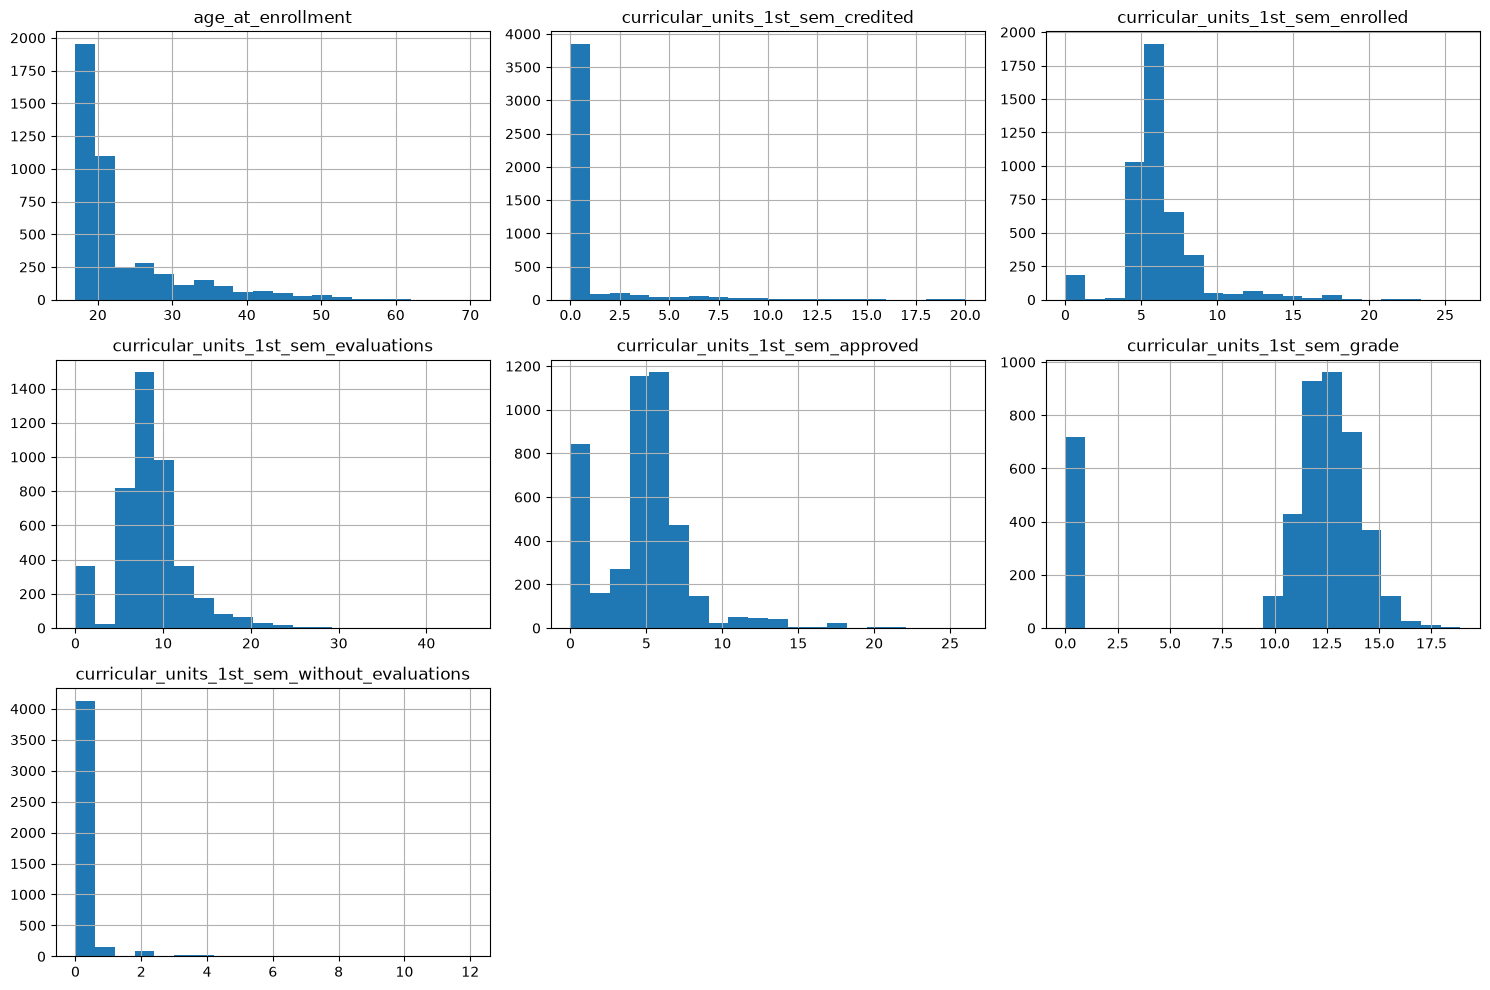

In [10]:
df_features[numerical_features].hist(
    figsize=(15, 10),
    bins=20
)

plt.tight_layout()
plt.show()

In [11]:
df_features[numerical_features].skew().round(2)

age_at_enrollment                               2.05
curricular_units_1st_sem_credited               4.17
curricular_units_1st_sem_enrolled               1.62
curricular_units_1st_sem_evaluations            0.98
curricular_units_1st_sem_approved               0.77
curricular_units_1st_sem_grade                 -1.57
curricular_units_1st_sem_without_evaluations    8.21
dtype: float64

In [12]:
zero_values = pd.DataFrame({
    "zero_count": (df_features[numerical_features] == 0).sum(),
    "zero_percentage": (df_features[numerical_features] == 0).mean() * 100
})

zero_values.round(2)

,zero_count,zero_percentage
age_at_enrollment,0,0.00
curricular_units_1st_sem_credited,3847,86.96
curricular_units_1st_sem_enrolled,180,4.07
curricular_units_1st_sem_evaluations,349,7.89
curricular_units_1st_sem_approved,718,16.23
curricular_units_1st_sem_grade,718,16.23
curricular_units_1st_sem_without_evaluations,4130,93.35


### Numerical Features - Observations

- Age at enrollment is right-skewed (2.05)
- 86.96% of students have no credited units
- 93.35% of students have no units without evaluations
- 4.07% of students have zero enrolled units
- 16.23% of students have zero approved units and
  16.23% have a grade of zero
- Zero values are retained as they may represent
  meaningful academic information
- All numerical features will initially be retained

## Feature Engineering

### Feature Creation - Approval Rate

The approval rate measures the proportion of enrolled
curricular units successfully approved by a student.

This feature accounts for differences in academic
workload between students.

In [13]:
df_features[
    df_features["curricular_units_1st_sem_approved"] >
    df_features["curricular_units_1st_sem_enrolled"]
].shape[0]

0

In [14]:
#zero enrolled units
zero_enrolled = df_features[
    df_features["curricular_units_1st_sem_enrolled"] == 0
]

zero_enrolled.describe().T

,count,mean,std,min,25%,50%,75%,max
scholarship_holder,180.0,0.244444,0.430956,0.0,0.0,0.0,0.0,1.0
age_at_enrollment,180.0,20.138889,3.579526,17.0,18.0,19.0,20.0,38.0
international,180.0,0.033333,0.180006,0.0,0.0,0.0,0.0,1.0
curricular_units_1st_sem_credited,180.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
curricular_units_1st_sem_enrolled,180.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
curricular_units_1st_sem_evaluations,180.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
curricular_units_1st_sem_approved,180.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
curricular_units_1st_sem_grade,180.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
curricular_units_1st_sem_without_evaluations,180.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0


In [15]:
df_features["approval_rate_1st_sem"] = (
    df_features["curricular_units_1st_sem_approved"] /
    df_features["curricular_units_1st_sem_enrolled"].replace(0, np.nan)
)

df_features["approval_rate_1st_sem"].describe()

count    4244.000000
mean        0.727484
std         0.342821
min         0.000000
25%         0.600000
50%         0.857143
75%         1.000000
max         1.000000
Name: approval_rate_1st_sem, dtype: float64

In [16]:
df_features["approval_rate_1st_sem"].isna().sum()

np.int64(180)

### Approval Rate - Observations

- Created a new feature to measure academic performance
  relative to the number of enrolled curricular units
- The average approval rate is 72.75%
- The median approval rate is 85.71%
- No students have more approved units than enrolled units
- 180 students have zero enrolled units, resulting in
  undefined approval rates (NaN)
- These students will be retained, and the handling of
  undefined approval rates will be discussed with the team

## Further Feature Analysis

To investigate the relationship between the selected
features and dropout, only students with known academic
outcomes will be considered.

Graduate = 0
Dropout = 1

Enrolled students will be retained separately for
future predictions.

In [17]:
df_model = df_features[df_features["target"] != "Enrolled"].copy()

df_enrolled = df_features[df_features["target"] == "Enrolled"].copy()

df_model["target"] = df_model["target"].map({
    "Graduate": 0,
    "Dropout": 1
})

df_model["target"].value_counts()

target
0    2209
1    1421
Name: count, dtype: int64

In [18]:
X = df_model.drop(columns="target")
y = df_model["target"]

In [19]:


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=0,
    stratify=y
)

In [20]:
train_for_eda = X_train.copy()
train_for_eda["target"] = y_train

train_for_eda.head()

,scholarship_holder,age_at_enrollment,international,curricular_units_1st_sem_credited,curricular_units_1st_sem_enrolled,curricular_units_1st_sem_evaluations,curricular_units_1st_sem_approved,curricular_units_1st_sem_grade,curricular_units_1st_sem_without_evaluations,approval_rate_1st_sem,target
1887,0,51,0,0,4,4,0,0.000000,0,0.000000,1
425,0,20,0,0,7,7,6,13.916667,0,0.857143,0
1033,1,18,0,0,5,7,4,13.250000,0,0.800000,0
2901,0,27,0,0,5,5,0,0.000000,0,0.000000,1
1108,0,22,0,7,12,12,7,11.000000,0,0.583333,1


### Age at Enrollment

Investigating whether age at enrollment differs
between students who graduate and students who drop out.

In [21]:
train_for_eda.groupby("target")[
    "age_at_enrollment"
].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
target,,,,,,,,
0,1767.0,21.87,6.89,17.0,18.0,19.0,21.0,62.0
1,1137.0,26.11,8.73,18.0,19.0,23.0,30.0,70.0


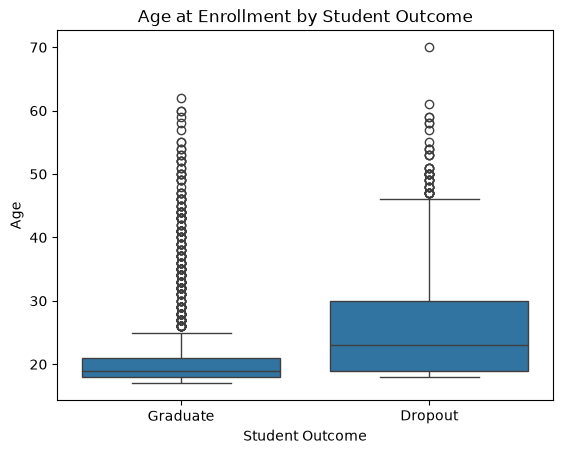

In [22]:
sns.boxplot(
    data=train_for_eda,
    x="target",
    y="age_at_enrollment"
)

plt.xticks([0, 1], ["Graduate", "Dropout"])
plt.title("Age at Enrollment by Student Outcome")
plt.xlabel("Student Outcome")
plt.ylabel("Age")
plt.show()

### Age at Enrollment - Observations

- Dropout students are older on average than graduates
  (26.11 vs. 21.87 years)
- The median age is 23 for dropout students and 19
  for graduates
- Dropout students present a greater variability in age
- Higher age at enrollment appears to be associated
  with dropout, although this does not imply causation

Decision: retain age as a numerical feature and apply
scaling during preprocessing where appropriate

### International Status

Investigating whether dropout rates differ between
international and non-international students.

In [23]:
train_for_eda.groupby("international")["target"].agg(
    ["count", "sum", "mean"]
).round(4)

,count,sum,mean
international,,,
0,2833,1111,0.3922
1,71,26,0.3662


In [24]:
international_dropout_rate = (
    train_for_eda.groupby("international")["target"].mean() * 100
)

international_dropout_rate.round(2)

international
0    39.22
1    36.62
Name: target, dtype: float64

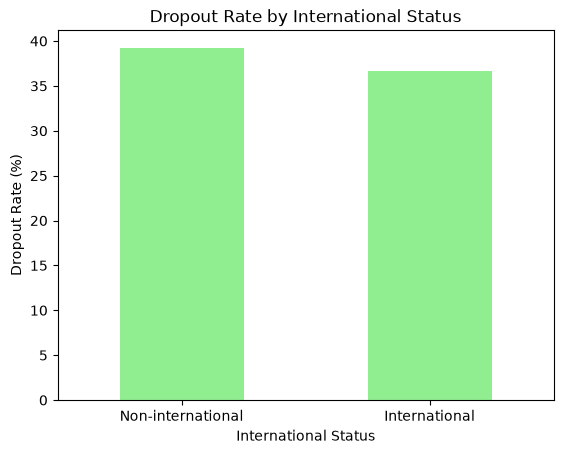

In [25]:
international_dropout_rate.plot(kind="bar", color="lightgreen")

plt.xticks(
    [0, 1],
    ["Non-international", "International"],
    rotation=0
)

plt.title("Dropout Rate by International Status")
plt.xlabel("International Status")
plt.ylabel("Dropout Rate (%)")
plt.show()

### International Status - Observations

- Non-international students have a dropout rate of 39.22%,
  compared to 36.62% for international students.
- The difference is relatively small (2.60 percentage points).
- International students are underrepresented in the training
  dataset (71 compared to 2,833 non-international students).
- Further evidence would be needed to determine whether
  international status is a relevant predictor of dropout.

Decision: retain the original binary encoding (0 and 1).

### First-Semester Approved Units

Investigating whether students who drop out approve fewer
curricular units in the first semester than students
who graduate.

In [26]:
train_for_eda.groupby("target")[
    "curricular_units_1st_sem_approved"
].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
target,,,,,,,,
0,1767.0,6.19,2.59,0.0,5.0,6.0,7.0,26.0
1,1137.0,2.52,2.90,0.0,0.0,2.0,4.0,21.0


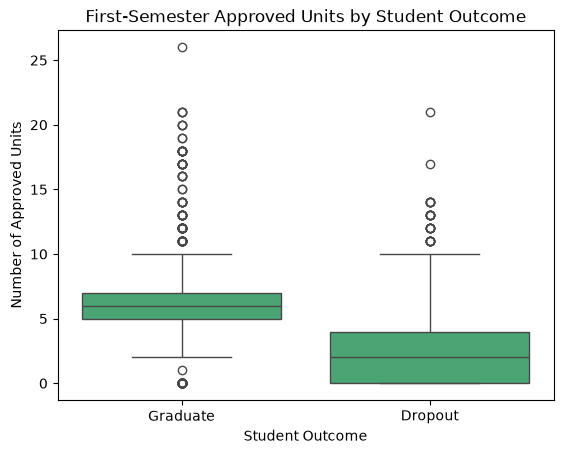

In [27]:
sns.boxplot(
    data=train_for_eda,
    x="target",
    y="curricular_units_1st_sem_approved",
    color="mediumseagreen"
)

plt.xticks([0, 1], ["Graduate", "Dropout"])
plt.title("First-Semester Approved Units by Student Outcome")
plt.xlabel("Student Outcome")
plt.ylabel("Number of Approved Units")
plt.show()

In [28]:
train_for_eda[
    train_for_eda["curricular_units_1st_sem_approved"] == 0
]["target"].value_counts(normalize=True) * 100

target
1    87.735849
0    12.264151
Name: proportion, dtype: float64

### First-Semester Approved Units - Observations

- Graduates approve an average of 6.19 units, compared
  to 2.52 for dropout students.
- The median is 6 units for graduates and 2 for
  dropout students.
- Dropout students approve approximately 59% fewer
  units on average.
- Among students with zero approved units, 87.74%
  dropped out.
- The results suggest a strong association between
  first-semester approved units and student dropout,
  supporting our initial hypothesis.

Decision: retain this numerical feature for modelling.

### First-Semester Grades

Investigating whether students who drop out have lower
first-semester grades than students who graduate.

In [29]:
train_for_eda.groupby("target")[
    "curricular_units_1st_sem_grade"
].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
target,,,,,,,,
0,1767.0,12.61,2.75,0.0,12.12,13.00,13.85,18.88
1,1137.0,7.16,6.05,0.0,0.00,10.75,12.17,18.00


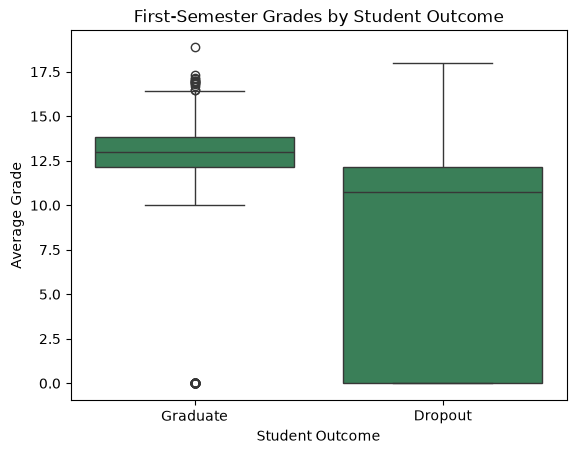

In [30]:
sns.boxplot(
    data=train_for_eda,
    x="target",
    y="curricular_units_1st_sem_grade",
    color="seagreen"
)

plt.xticks([0, 1], ["Graduate", "Dropout"])
plt.title("First-Semester Grades by Student Outcome")
plt.xlabel("Student Outcome")
plt.ylabel("Average Grade")
plt.show()

In [31]:
pd.crosstab(
    train_for_eda["curricular_units_1st_sem_approved"] == 0,
    train_for_eda["curricular_units_1st_sem_grade"] == 0
)

curricular_units_1st_sem_grade,False,True
curricular_units_1st_sem_approved,,
False,2374,0
True,0,530


In [32]:
#do graduates still achieve higher grades when we exclude zero grades?
train_for_eda[
    train_for_eda["curricular_units_1st_sem_grade"] > 0
].groupby("target")[
    "curricular_units_1st_sem_grade"
].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
target,,,,,,,,
0,1702.0,13.09,1.25,10.0,12.20,13.0,13.88,18.88
1,672.0,12.12,1.36,9.8,11.25,12.0,12.96,18.00


### First-Semester Grades - Observations

- Graduates have a higher average grade than dropout
  students (12.61 vs. 7.16).
- The median grade is 13 for graduates and 10.75
  for dropout students.
- Dropout students present greater variability in grades.
- Among students with zero grades, 87.74% dropped out.
- All students with zero approved units also have zero
  grades, and vice versa, suggesting some overlap
  between these features.
- When excluding zero grades, graduates still achieve
  higher average grades than dropout students
  (13.09 vs. 12.12).
- However, the difference becomes considerably smaller,
  indicating that zero grades contribute substantially
  to the original difference.

Decision: retain both features for now and investigate
their relationship through correlation analysis.

### First-Semester Approval Rate

Investigating whether students who drop out have lower
approval rates than students who graduate, accounting
for differences in academic workload.

In [33]:
train_for_eda.groupby("target")[
    "approval_rate_1st_sem"
].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
target,,,,,,,,
0,1704.0,0.93,0.11,0.0,0.86,1.0,1.00,1.0
1,1074.0,0.40,0.37,0.0,0.00,0.4,0.71,1.0


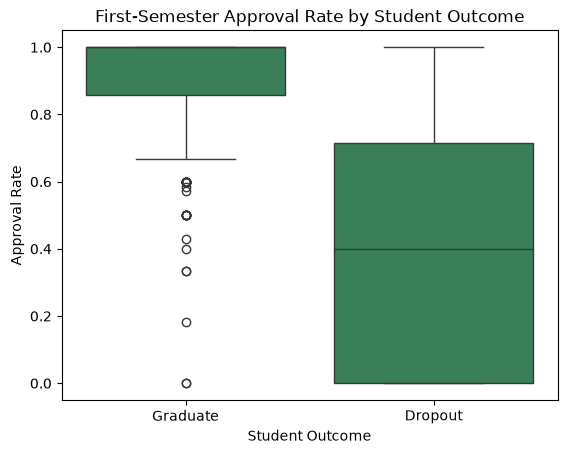

In [34]:
sns.boxplot(
    data=train_for_eda,
    x="target",
    y="approval_rate_1st_sem",
    color="seagreen"
)

plt.xticks([0, 1], ["Graduate", "Dropout"])
plt.title("First-Semester Approval Rate by Student Outcome")
plt.xlabel("Student Outcome")
plt.ylabel("Approval Rate")
plt.show()

In [35]:
# check undefined approval rates
train_for_eda[
    train_for_eda["approval_rate_1st_sem"].isna()
]["target"].value_counts()

target
0    63
1    63
Name: count, dtype: int64

### First-Semester Approval Rate - Observations

- Graduates have an average approval rate of 93%,
  compared to 40% for dropout students.
- The median approval rate is 100% for graduates
  and 40% for dropout students.
- Dropout students present considerably greater
  variability in their approval rates.
- 126 students in the training dataset have undefined
  approval rates due to zero enrolled units.
- The approval rate appears to be a potentially useful
  predictor of student dropout.

Decision: propose this engineered feature for modelling,
subject to the handling of undefined values.

## Feature Selection - Correlation Analysis

Pearson correlation is used to investigate relationships
between the selected features and the target variable,
as well as potential redundancy between features.

In [36]:
correlation_matrix = train_for_eda.corr(numeric_only=True)

correlation_matrix.round(2)

,scholarship_holder,age_at_enrollment,international,curricular_units_1st_sem_credited,curricular_units_1st_sem_enrolled,curricular_units_1st_sem_evaluations,curricular_units_1st_sem_approved,curricular_units_1st_sem_grade,curricular_units_1st_sem_without_evaluations,approval_rate_1st_sem,target
scholarship_holder,1.00,-0.21,-0.03,-0.09,-0.01,-0.05,0.18,0.20,-0.07,0.29,-0.31
age_at_enrollment,-0.21,1.00,-0.00,0.23,0.14,0.15,-0.07,-0.17,0.09,-0.28,0.26
international,-0.03,-0.00,1.00,0.01,0.01,0.01,0.01,-0.00,0.02,0.01,-0.01
curricular_units_1st_sem_credited,-0.09,0.23,0.01,1.00,0.78,0.57,0.63,0.13,0.14,0.13,-0.03
curricular_units_1st_sem_enrolled,-0.01,0.14,0.01,0.78,1.00,0.70,0.77,0.38,0.14,0.21,-0.15
curricular_units_1st_sem_evaluations,-0.05,0.15,0.01,0.57,0.70,1.00,0.56,0.43,0.27,0.18,-0.06
curricular_units_1st_sem_approved,0.18,-0.07,0.01,0.63,0.77,0.56,1.00,0.71,0.00,0.79,-0.55
curricular_units_1st_sem_grade,0.20,-0.17,-0.00,0.13,0.38,0.43,0.71,1.00,-0.07,0.86,-0.52
curricular_units_1st_sem_without_evaluations,-0.07,0.09,0.02,0.14,0.14,0.27,0.00,-0.07,1.00,-0.13,0.08
approval_rate_1st_sem,0.29,-0.28,0.01,0.13,0.21,0.18,0.79,0.86,-0.13,1.00,-0.73


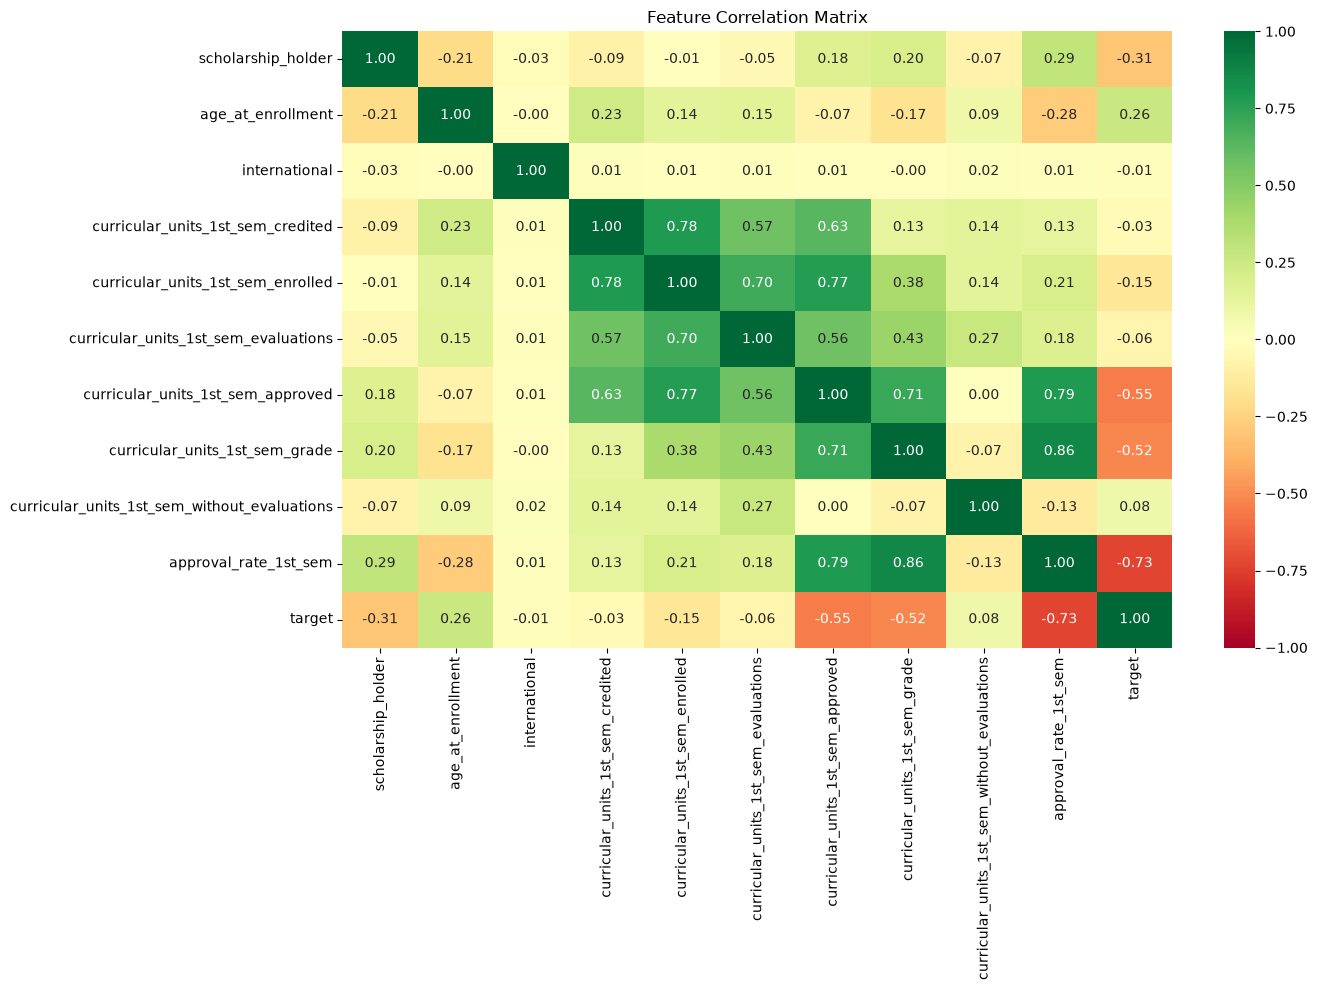

In [37]:
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="RdYlGn",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()

In [38]:
#correlations with the target
corr_to_target = (
    correlation_matrix["target"]
    .drop("target")
    .sort_values(key=abs, ascending=False)
)

corr_to_target.round(3)

approval_rate_1st_sem                          -0.727
curricular_units_1st_sem_approved              -0.551
curricular_units_1st_sem_grade                 -0.521
scholarship_holder                             -0.312
age_at_enrollment                               0.261
curricular_units_1st_sem_enrolled              -0.149
curricular_units_1st_sem_without_evaluations    0.081
curricular_units_1st_sem_evaluations           -0.064
curricular_units_1st_sem_credited              -0.032
international                                  -0.008
Name: target, dtype: float64

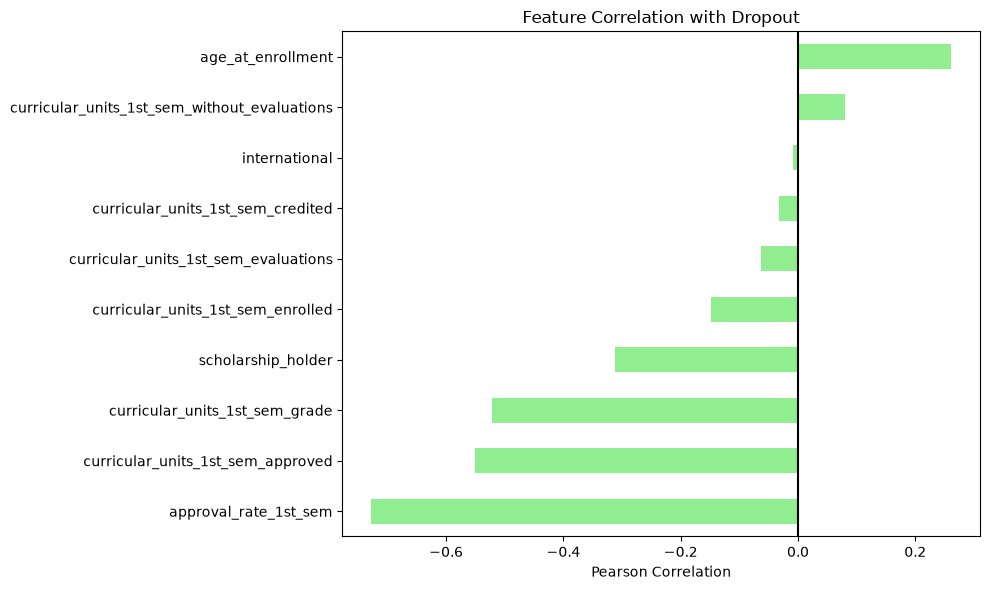

In [39]:
corr_to_target.sort_values().plot(
    kind="barh",
    color="lightgreen",
    figsize=(10, 6)
)

plt.axvline(0, color="black")
plt.title("Feature Correlation with Dropout")
plt.xlabel("Pearson Correlation")
plt.tight_layout()
plt.show()

### Correlation Analysis - Observations

- The newly created approval rate has the strongest
  negative correlation with dropout (-0.727) among
  the assigned features.

- Approved units (-0.551) and grades (-0.521) also
  show relatively strong negative correlations
  with dropout.

- Scholarship holder presents a negative correlation
  with dropout (-0.312).

- Age at enrollment presents a positive correlation
  with dropout (0.261).

- International status presents almost no linear
  correlation with dropout (-0.008).

- Several academic features are strongly correlated
  with each other, suggesting potential redundancy.

- Approval rate is strongly correlated with grade
  (0.86) and approved units (0.79).

- Approval rate correlations exclude students with
  undefined approval rates.

Decision: retain the original features initially
and recommend evaluating the newly created approval
rate during model development.

Correlation does not imply causation, and weak
correlation does not necessarily indicate that a
feature has no predictive value.

## Feature Transformation

Numerical features will be standardised for models
that are sensitive to differences in feature scales.

Binary features will retain their original 0 and 1
encoding.

Scaling will be fitted on training data only as part
of the shared Machine Learning pipeline.

In [40]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

In [41]:
numerical_pipeline = Pipeline([
    ("scaling", StandardScaler())
])

In [42]:
preprocessor = ColumnTransformer([
    ("numerical", numerical_pipeline, numerical_features),
    ("binary", "passthrough", binary_features)
])

preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('binary', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``featu

### Preprocessing Decisions

- StandardScaler will be applied to the seven
  original numerical features for scale-sensitive
  Machine Learning models.

- Scholarship holder and international status
  will retain their binary encoding.

- No categorical grouping or OneHotEncoding
  is required for the assigned features.

- The newly created approval rate is not yet
  included in the preprocessing pipeline due
  to its undefined values.

- The scaler will be fitted during model training
  using training data only.

- This preprocessor will be integrated with the
  transformations developed by the other team members.

## Final Feature Engineering Recommendations

| Feature | Recommendation |
|---|---|
| Scholarship holder | Keep binary encoding |
| Age at enrollment | Keep and scale |
| International | Keep binary encoding |
| Credited units | Keep and scale |
| Enrolled units | Keep and scale |
| Evaluations | Keep and scale |
| Approved units | Keep and scale |
| Grade | Keep and scale |
| Without evaluations | Keep and scale |
| Approval rate | New feature proposed for modelling |

Scaling is recommended for scale-sensitive models.

No original features or observations have been removed.

Valid zero values have been retained.

The approval rate is recommended as an additional
feature, subject to agreement on handling undefined
values and evaluation during model development.

The shared train/test split must be confirmed
before finalising feature selection.

The timing of first-semester information must also
be considered when defining the prediction point.